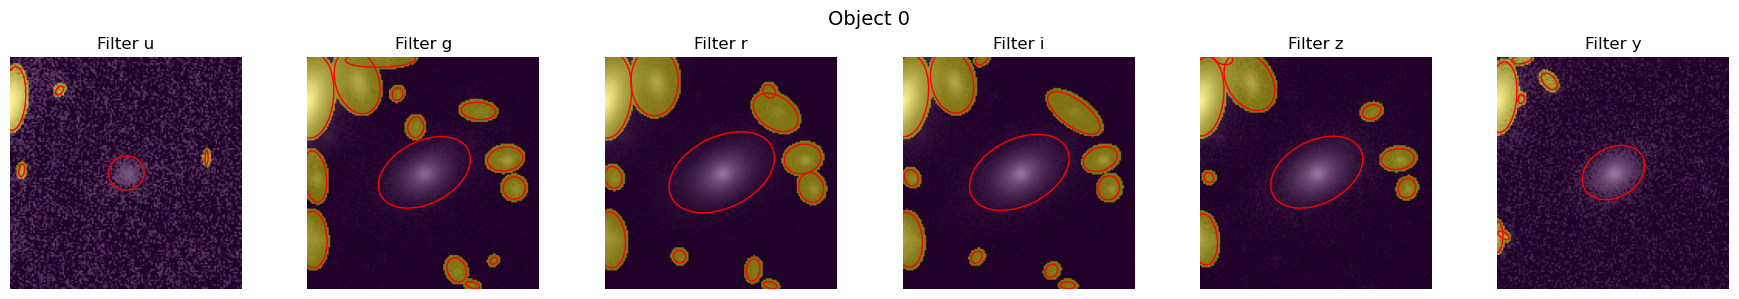

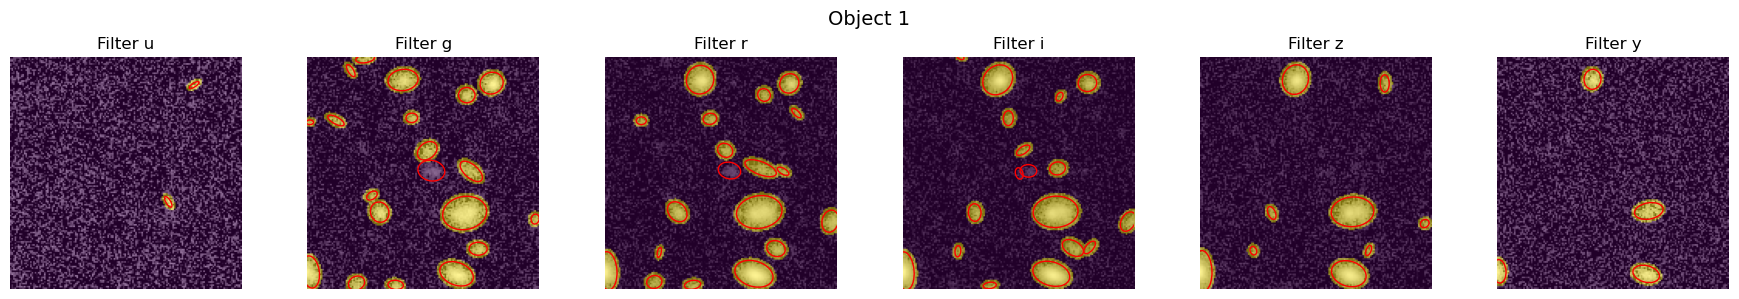

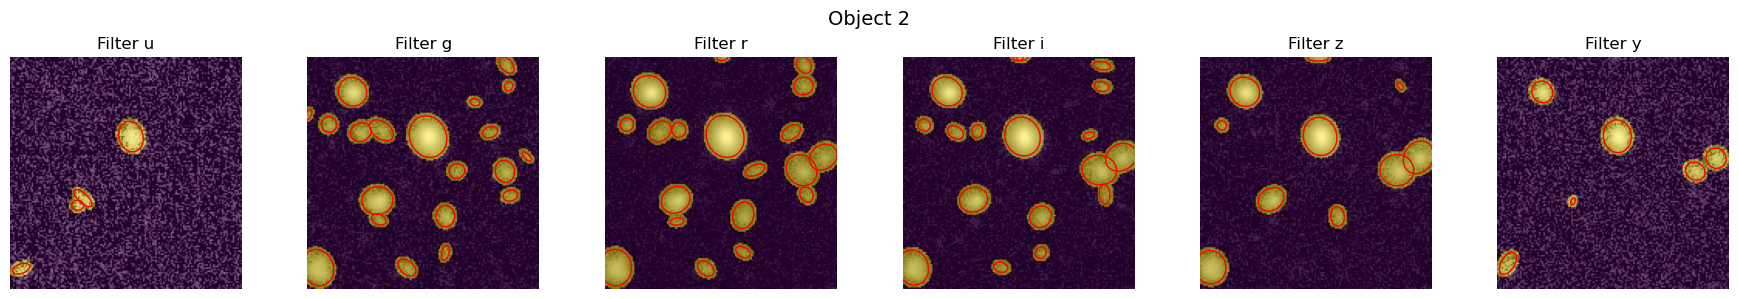

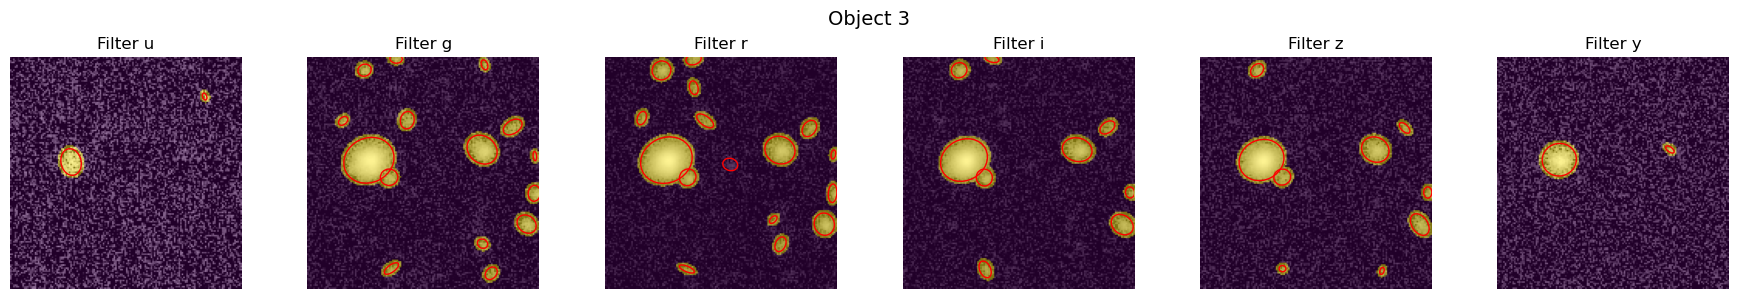

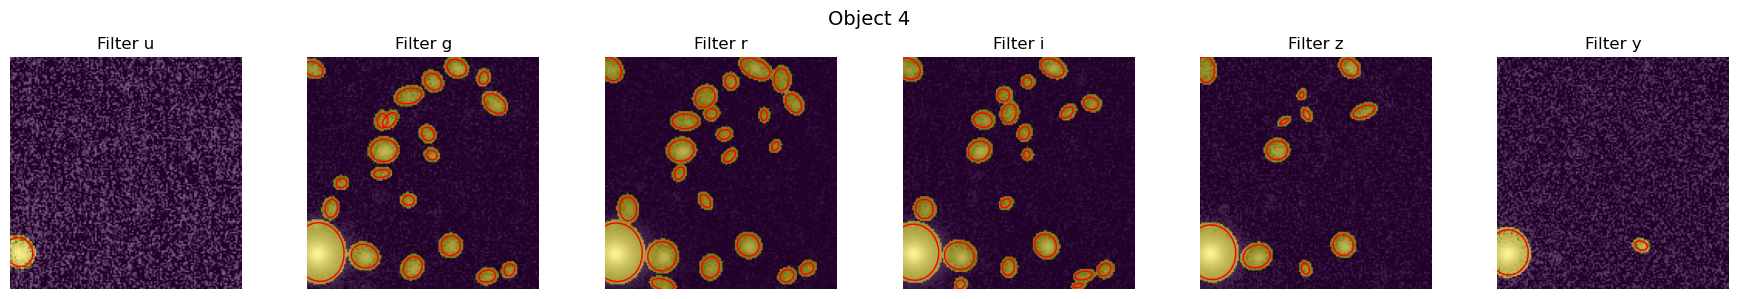

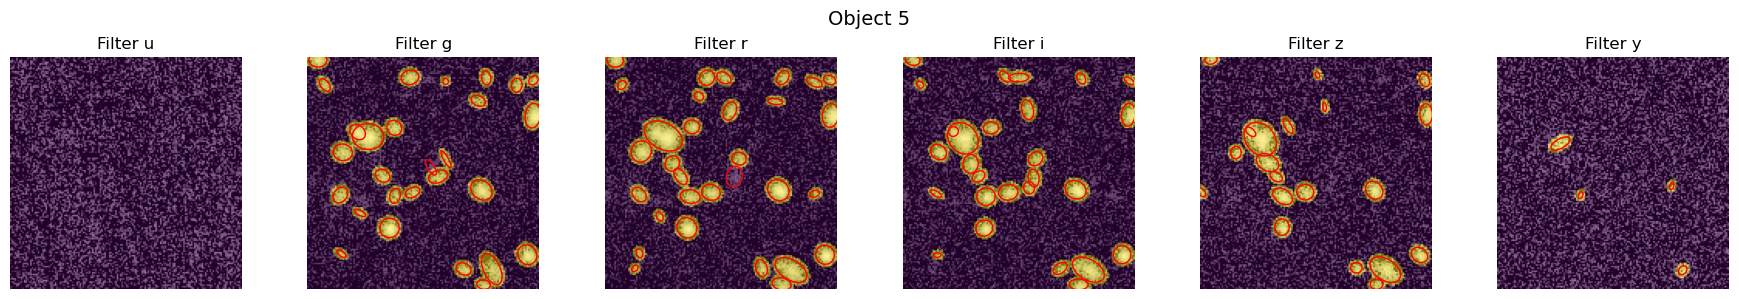

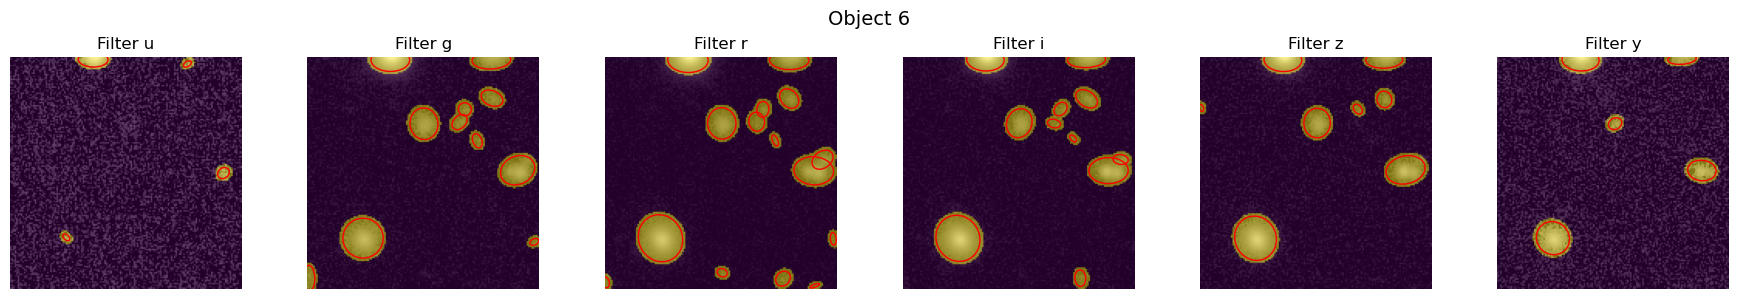

In [9]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import sep
from matplotlib import rcParams
import math
from astropy.stats import sigma_clipped_stats
from matplotlib.patches import Ellipse

def change_image(image):
    """
    Display a galaxy image with automatic astronomical contrast scaling.
    Only requires the image array.
    """

    # Robust background estimate
    mean, median, std = sigma_clipped_stats(image, sigma=3)

    # Shift background to zero
    img = image - median

    # Clip negative/background-dominated pixels
    img = np.clip(img, 0, None)

    # Robust upper scale
    vmax = np.percentile(img, 98)

    # Asinh stretch
    stretched = np.arcsinh(10 * img / vmax)
    stretched /= stretched.max()
    return stretched
def zscale(image, contrast=0.25, nsamples=1000):
    """
    Approximate IRAF/DS9 zscale limits.
    """

    samples = image[np.isfinite(image)].ravel()

    if len(samples) > nsamples:
        idx = np.random.choice(len(samples), nsamples, replace=False)
        samples = samples[idx]

    samples.sort()

    n = len(samples)
    center = n // 2
    median = samples[center]

    x = np.arange(n)

    slope, intercept = np.polyfit(x, samples, 1)

    slope /= contrast

    z1 = median - slope * center
    z2 = median + slope * (n - center)

    return z1, z2
def detect_sources(image, thresh = 1.3, deblend_nthresh = 32, deblend_cont = 0.0001):
    """
    This class runs sextractor with python and allows user to build necessary files for galfit.
    :param image: Array
    :param thresh: Sextractor parameter.
    :param deblend_nthresh: Sextractor parameter.
    :param deblend_cont: Sextractor parameter.
    """
    image = image
    #image = image.byteswap().newbyteorder()
    image = image.byteswap().view(image.dtype.newbyteorder())
    image = image.astype(np.float32)

    bkg = sep.Background(image)
    bkg_image = bkg.back()
    data_sub = image - bkg_image

    objects = sep.extract(data_sub, thresh,
                               err=bkg.globalrms,
                               deblend_nthresh=deblend_nthresh,
                               deblend_cont=deblend_cont)
    return objects
def showDetections(objects, ax):
    """
    This method shows the detected objects on the image.
    """
    for o in objects:
        ell = Ellipse(xy = (o['x']-1, o['y']-1), width=o['a']*6, height=o['b']*6,
                      angle=np.rad2deg(o['theta']), edgecolor='r', fc = 'None')
        ax.add_patch(ell)
def is_pixel_in_ellipse(image_size, center, a, b, theta, scale = 1, ap = 0):
    # Generate the grid of coordinates
    a = a*scale +ap
    b = b*scale +ap
    y, x = np.indices(image_size)
    theta = np.deg2rad(theta)

    # Shift the coordinates to the ellipse center
    x_shifted = x - center[0]
    y_shifted = y - center[1]

    # Apply the rotation matrix to the shifted coordinates
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    x_rot = x_shifted * cos_theta + y_shifted * sin_theta
    y_rot = -x_shifted * sin_theta + y_shifted * cos_theta

    # Ellipse equation (x_rot / a)^2 + (y_rot / b)^2 <= 1
    ellipse_mask = ((x_rot / a) ** 2 + (y_rot / b) ** 2) <= 1
    return ellipse_mask
def make_mask(image, objects, additionalSize = 2, centralSourceDistance = 10, scale = 3):
    result = np.zeros(image.shape)
    centralPositionX, centralPositionY = image.shape[0]/2, image.shape[1]/2
    for o in objects:
        dist = np.sqrt((o['x'] - centralPositionX)**2 + (o['y'] - centralPositionY)**2)
        if dist>centralSourceDistance:
            mask = is_pixel_in_ellipse(image.shape,
                               (o['x'] - 1, o['y'] - 1),
                                      o['a'],
                                      o['b'],
                                      np.rad2deg(o['theta']),
                                      scale = scale,
                                      ap=additionalSize)
            result[mask] = 1
    return result

hdul = fits.open("galaxies_images_probe.fits")

filter_names = ['u', 'g', 'r', 'i', 'z', 'y']

n_objects = 7
n_filters = 6

for obj in range(n_objects):

    fig, axes = plt.subplots(1, n_filters, figsize=(3 * n_filters, 3))
    fig.suptitle(f"Object {obj}", fontsize=14)

    for f in range(n_filters):

        ax = axes[f]

        i = obj * n_filters + f + 1
        image = hdul[i].data

        # bezpieczeństwo typu danych
        data = np.asarray(image).astype(image.dtype.newbyteorder('='))

        gals = detect_sources(data)
        mask = make_mask(data, gals)
        showDetections(gals, ax)

        data = change_image(data)
        #vmin, vmax = np.percentile(data, [10, 97])
        im = ax.imshow(data, cmap="gray", origin="lower")#, vmin = vmin, vmax=vmax)
        ax.imshow(mask, alpha = 0.5)
        ax.set_title(f"Filter {filter_names[f]}")
        ax.axis("off")

    plt.tight_layout()
    plt.savefig('images/%i.png'%obj)

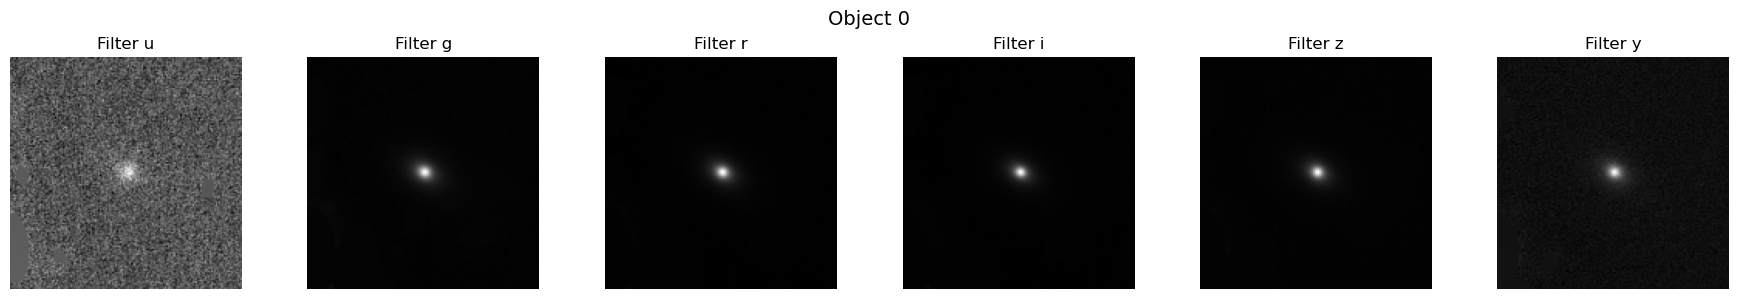

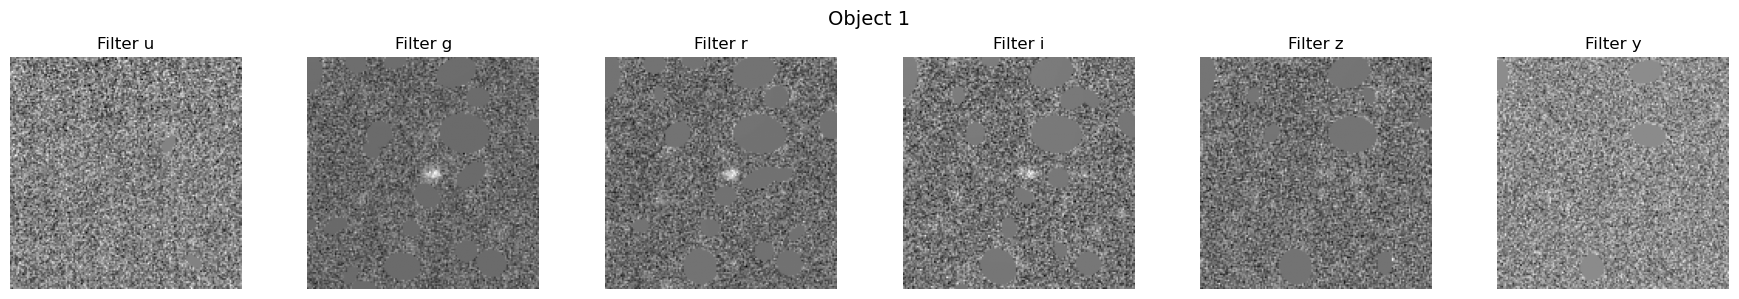

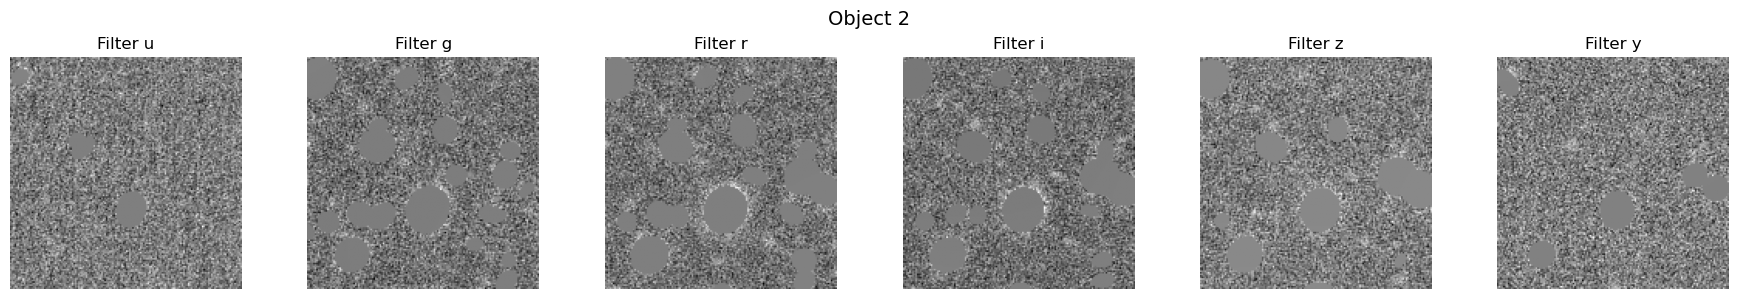

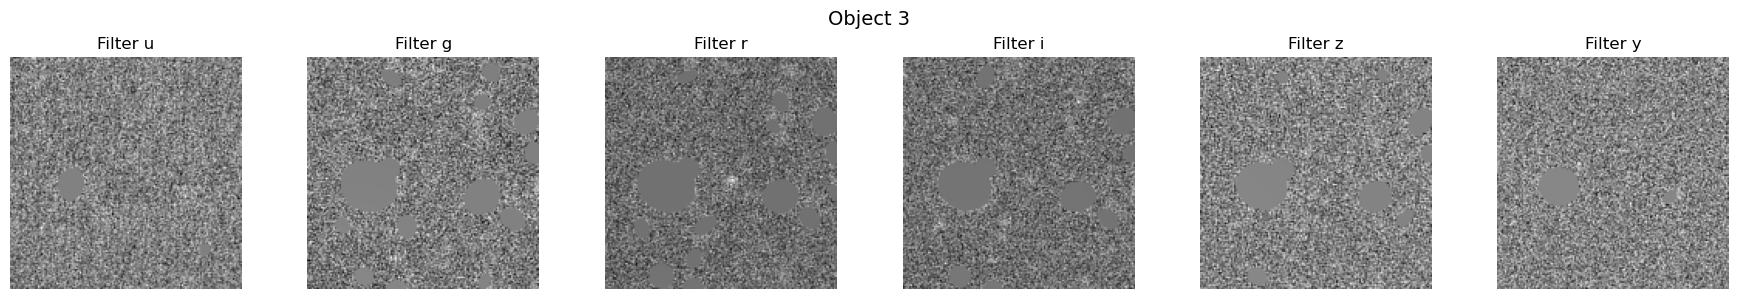

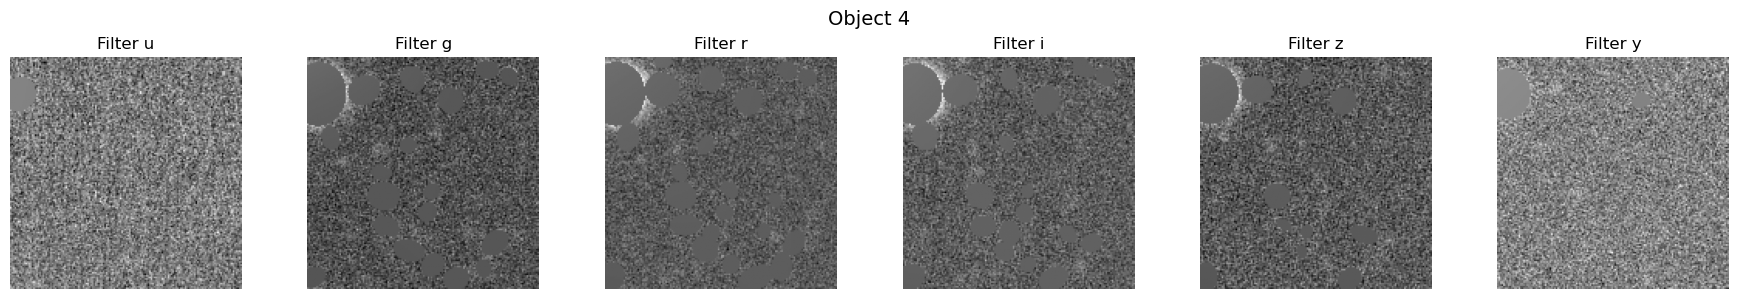

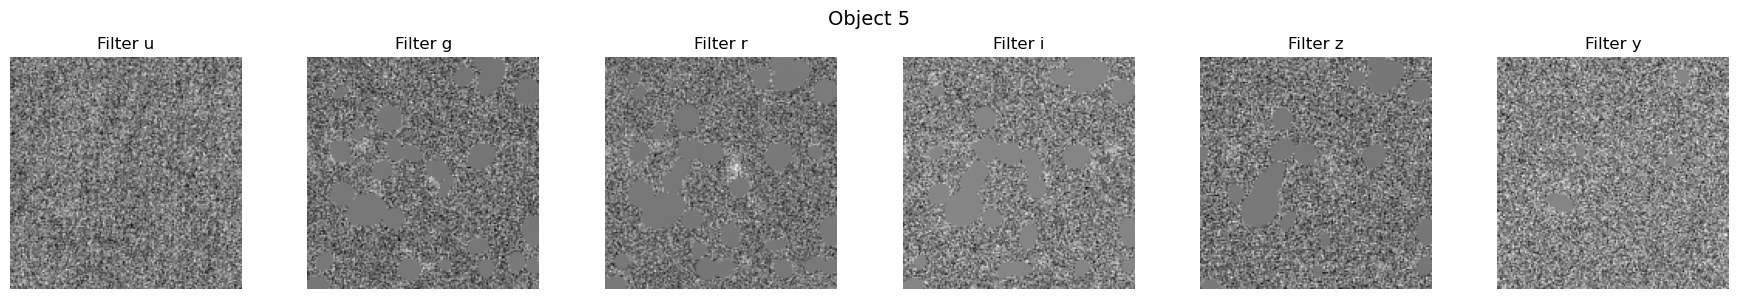

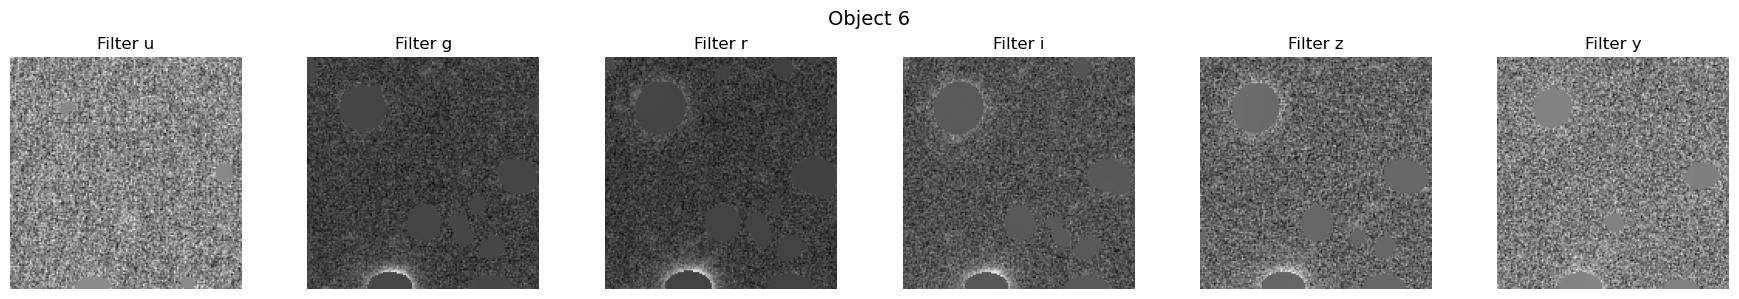

In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import sep
from matplotlib import rcParams
import math
from astropy.stats import sigma_clipped_stats
from matplotlib.patches import Ellipse

def change_image(image):
    """
    Display a galaxy image with automatic astronomical contrast scaling.
    Only requires the image array.
    """

    # Robust background estimate
    mean, median, std = sigma_clipped_stats(image, sigma=3)

    # Shift background to zero
    img = image - median

    # Clip negative/background-dominated pixels
    img = np.clip(img, 0, None)

    # Robust upper scale
    vmax = np.percentile(img, 98)

    # Asinh stretch
    stretched = np.arcsinh(10 * img / vmax)
    stretched /= stretched.max()
    return stretched
def zscale(image, contrast=0.25, nsamples=1000):
    """
    Approximate IRAF/DS9 zscale limits.
    """

    samples = image[np.isfinite(image)].ravel()

    if len(samples) > nsamples:
        idx = np.random.choice(len(samples), nsamples, replace=False)
        samples = samples[idx]

    samples.sort()

    n = len(samples)
    center = n // 2
    median = samples[center]

    x = np.arange(n)

    slope, intercept = np.polyfit(x, samples, 1)

    slope /= contrast

    z1 = median - slope * center
    z2 = median + slope * (n - center)

    return z1, z2
def detect_sources(image, thresh = 1.3, deblend_nthresh = 32, deblend_cont = 0.0001):
    """
    This class runs sextractor with python and allows user to build necessary files for galfit.
    :param image: Array
    :param thresh: Sextractor parameter.
    :param deblend_nthresh: Sextractor parameter.
    :param deblend_cont: Sextractor parameter.
    """
    image = image
    #image = image.byteswap().newbyteorder()
    image = image.byteswap().view(image.dtype.newbyteorder())
    image = image.astype(np.float32)

    bkg = sep.Background(image)
    bkg_image = bkg.back()
    data_sub = image - bkg_image

    objects = sep.extract(data_sub, thresh,
                               err=bkg.globalrms,
                               deblend_nthresh=deblend_nthresh,
                               deblend_cont=deblend_cont)
    return objects
def is_pixel_in_ellipse(image_size, center, a, b, theta, scale = 1, ap = 0):
    # Generate the grid of coordinates
    a = a*scale +ap
    b = b*scale +ap
    y, x = np.indices(image_size)
    theta = np.deg2rad(theta)

    # Shift the coordinates to the ellipse center
    x_shifted = x - center[0]
    y_shifted = y - center[1]

    # Apply the rotation matrix to the shifted coordinates
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    x_rot = x_shifted * cos_theta + y_shifted * sin_theta
    y_rot = -x_shifted * sin_theta + y_shifted * cos_theta

    # Ellipse equation (x_rot / a)^2 + (y_rot / b)^2 <= 1
    ellipse_mask = ((x_rot / a) ** 2 + (y_rot / b) ** 2) <= 1
    return ellipse_mask
def make_mask(image, objects, additionalSize = 2, centralSourceDistance = 10, scale = 3):
    result = np.zeros(image.shape)
    centralPositionX, centralPositionY = image.shape[0]/2, image.shape[1]/2
    for o in objects:
        dist = np.sqrt((o['x'] - centralPositionX)**2 + (o['y'] - centralPositionY)**2)
        if dist>centralSourceDistance:
            mask = is_pixel_in_ellipse(image.shape,
                               (o['x'] - 1, o['y'] - 1),
                                      o['a'],
                                      o['b'],
                                      np.rad2deg(o['theta']),
                                      scale = scale,
                                      ap=additionalSize)
            result[mask] = 1
    return result


hdul = fits.open("galaxies_images.fits")

filter_names = ['u', 'g', 'r', 'i', 'z', 'y']

n_objects = 90
n_filters = 6


for obj in range(n_objects):

    fig, axes = plt.subplots(1, n_filters, figsize=(3 * n_filters, 3))
    fig.suptitle(f"Object {obj}", fontsize=14)

    for f in range(n_filters):

        ax = axes[f]

        i = obj * n_filters + f + 1
        image = hdul[i].data

        # bezpieczeństwo typu danych
        data = np.asarray(image).astype(image.dtype.newbyteorder('='))

        bkg = sep.Background(data)
        data = data - bkg.back()
        
        gals = detect_sources(data)
        mask = make_mask(data, gals)
                
        # deleting objects
        clean = np.where(mask, bkg.back(), data)
                

        im = ax.imshow(clean, cmap="gray", origin="lower")#, vmin = vmin, vmax=vmax)
        #ax.imshow(mask, alpha = 0.5)
        ax.set_title(f"Filter {filter_names[f]}")
        ax.axis("off")

    plt.tight_layout()
    #plt.savefig('images/%i.png'%obj)